<a href="https://colab.research.google.com/github/ashishkonale2603/Data_Analysis_Practice/blob/main/DA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
df=pd.read_csv('hr_data.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   employee_id            14999 non-null  int64 
 1   number_project         14999 non-null  int64 
 2   average_montly_hours   14999 non-null  int64 
 3   time_spend_company     14999 non-null  int64 
 4   Work_accident          14999 non-null  int64 
 5   left                   14999 non-null  int64 
 6   promotion_last_5years  14999 non-null  int64 
 7   department             14999 non-null  object
 8   salary                 14999 non-null  object
dtypes: int64(7), object(2)
memory usage: 1.0+ MB


In [5]:
df.head(10)

,employee_id,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
0,1003,2,157,3,0,1,0,sales,low
1,1005,5,262,6,0,1,0,sales,medium
2,1486,7,272,4,0,1,0,sales,medium
3,1038,5,223,5,0,1,0,sales,low
4,1057,2,159,3,0,1,0,sales,low
5,1060,2,153,3,0,1,0,sales,low
6,1061,6,247,4,0,1,0,sales,low
7,1576,5,259,5,0,1,0,sales,low
8,1752,5,224,5,0,1,0,sales,low
9,1988,2,142,3,0,1,0,sales,low


In [6]:
# No. of Employees
print(df['employee_id'].nunique())

14999


In [7]:
# List of all Departments
print(df['department'].value_counts())

department
sales          4140
technical      2720
support        2229
IT             1227
product_mng     902
marketing       858
RandD           787
accounting      767
hr              739
management      630
Name: count, dtype: int64


In [8]:
# Highest headcount department
print(df.groupby('department')['department'].agg('count').sort_values(ascending=False).head(1))

department
sales    4140
Name: department, dtype: int64


In [9]:
# Lowest headcount department
print(df.groupby('department')['department'].agg('count').sort_values(ascending=True).head(1))

department
management    630
Name: department, dtype: int64


In [10]:
# Salary Distribution of Employees in Company
print(df['salary'].value_counts(normalize=True)*100)

salary
low       48.776585
medium    42.976198
high       8.247216
Name: proportion, dtype: float64


In [11]:
# Attrition Rate by Department
dept_attriation=df.groupby('department')['left'].agg(
    Total_Employees='count',
    Emp_left='sum',
    Attrition_rate=lambda x: round(x.mean() * 100, 2)
).reset_index().sort_values('Attrition_rate', ascending=False)
print('Attriation By Dept: \n',dept_attriation)

Attriation By Dept: 
     department  Total_Employees  Emp_left  Attrition_rate
3           hr              739       215           29.09
2   accounting              767       204           26.60
9    technical             2720       697           25.62
8      support             2229       555           24.90
7        sales             4140      1014           24.49
5    marketing              858       203           23.66
0           IT             1227       273           22.25
6  product_mng              902       198           21.95
1        RandD              787       121           15.37
4   management              630        91           14.44


In [12]:
# Attrition Rate by Salary
sal_attriation=df.groupby('salary')['left'].agg(
    Total_Employees='count',
    Emp_left='sum',
    Attrition_rate=lambda x: round(x.mean() * 100, 2)
).reset_index().sort_values('Attrition_rate', ascending=False)
print('Attriation By Slary: \n',sal_attriation)

Attriation By Slary: 
    salary  Total_Employees  Emp_left  Attrition_rate
1     low             7316      2172           29.69
2  medium             6446      1317           20.43
0    high             1237        82            6.63


In [13]:
# Attrition Rate by Promotion
prom_attriation=df.groupby('promotion_last_5years')['left'].agg(
    Total_Employees='count',
    Emp_left='sum',
    Attrition_rate=lambda x: round(x.mean() * 100, 2)
).reset_index().sort_values('Attrition_rate', ascending=False)
print('Attriation By promotion: \n',prom_attriation)

Attriation By promotion: 
    promotion_last_5years  Total_Employees  Emp_left  Attrition_rate
0                      0            14680      3552           24.20
1                      1              319        19            5.96


In [14]:
# Attrition Rate by Projects
proj_attrition=df.groupby('number_project')['left'].agg(
    Total_Employees='count',
    Emp_left='sum',
    Attrition_rate=lambda x: round(x.mean() * 100, 2)
).reset_index().sort_values('number_project')
print('Attriation By Project: \n',proj_attrition)

Attriation By Project: 
    number_project  Total_Employees  Emp_left  Attrition_rate
0               2             2388      1567           65.62
1               3             4055        72            1.78
2               4             4365       409            9.37
3               5             2761       612           22.17
4               6             1174       655           55.79
5               7              256       256          100.00


In [15]:
burnout_emp=df[(df['average_montly_hours'] >250) & (df['number_project'] >= 6)]
burnout_total=len(burnout_emp)
burnout_left=burnout_emp['left'].sum()
print(burnout_total)

856


In [16]:
print(dept_attriation.to_string(index=False))
print(sal_attriation.to_string(index=False))
print(prom_attriation.to_string(index=False))

 department  Total_Employees  Emp_left  Attrition_rate
         hr              739       215           29.09
 accounting              767       204           26.60
  technical             2720       697           25.62
    support             2229       555           24.90
      sales             4140      1014           24.49
  marketing              858       203           23.66
         IT             1227       273           22.25
product_mng              902       198           21.95
      RandD              787       121           15.37
 management              630        91           14.44
salary  Total_Employees  Emp_left  Attrition_rate
   low             7316      2172           29.69
medium             6446      1317           20.43
  high             1237        82            6.63
 promotion_last_5years  Total_Employees  Emp_left  Attrition_rate
                     0            14680      3552           24.20
                     1              319        19            5.

In [17]:
df.shape

(14999, 9)

In [18]:
df.head()

,employee_id,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
0,1003,2,157,3,0,1,0,sales,low
1,1005,5,262,6,0,1,0,sales,medium
2,1486,7,272,4,0,1,0,sales,medium
3,1038,5,223,5,0,1,0,sales,low
4,1057,2,159,3,0,1,0,sales,low


In [19]:
df.dtypes

,0
employee_id,int64
number_project,int64
average_montly_hours,int64
time_spend_company,int64
Work_accident,int64
left,int64
promotion_last_5years,int64
department,object
salary,object


In [20]:
# null values
print(df.isnull().count())

employee_id              14999
number_project           14999
average_montly_hours     14999
time_spend_company       14999
Work_accident            14999
left                     14999
promotion_last_5years    14999
department               14999
salary                   14999
dtype: int64


In [21]:
# primary key duplicates
df['employee_id'].duplicated().sum()

np.int64(0)

In [22]:
df.describe()

,employee_id,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,45424.627575,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,25915.900127,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,1003.000000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,22872.500000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,45448.000000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,67480.500000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,99815.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [23]:
# unique departments
print('All departments: \n',df['department'].unique())

All departments: 
 ['sales' 'accounting' 'hr' 'technical' 'support' 'management' 'IT'
 'product_mng' 'marketing' 'RandD']


In [24]:
# unique salary
print('All Salary: ', df['salary'].unique())

All Salary:  ['low' 'medium' 'high']


## Visualization

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_1309/425627126.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dept_attr, x='left', y='department', ax=axes[0, 0], palette='Blues_r')
/tmp/ipykernel_1309/425627126.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sal_attr, x='salary', y='left', order=sal_order, ax=axes[0, 1], palette='Reds_r')
/tmp/ipykernel_1309/425627126.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=proj_attr, x='number_project', y='left', ax=axes[1, 0], palette='Oranges_r')


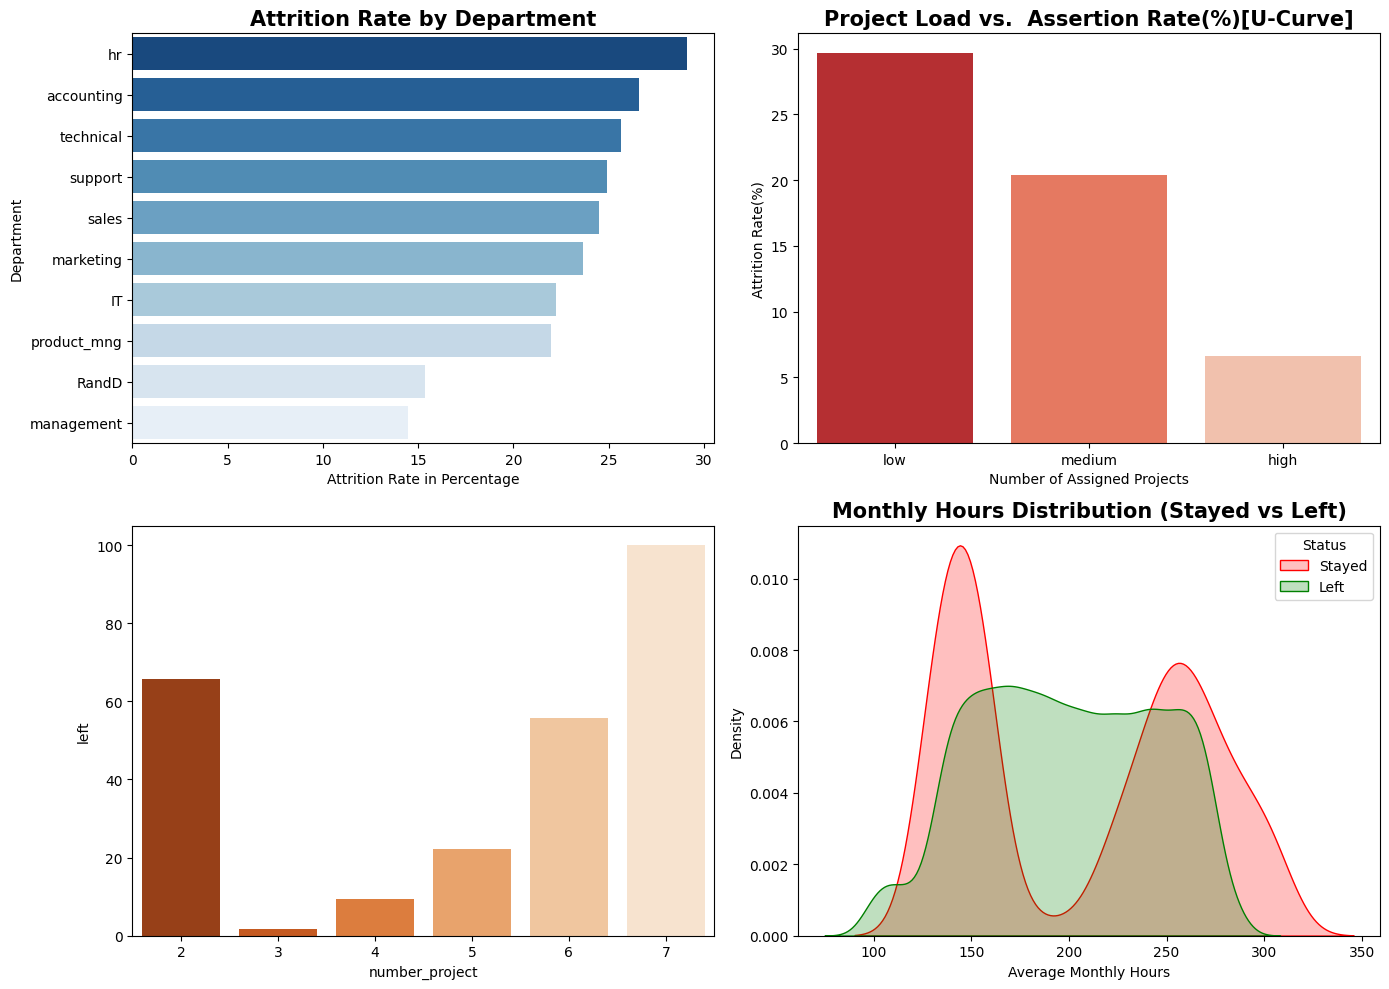

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# fig 1
dept_attr = df.groupby('department')['left'].mean().reset_index()
dept_attr['left'] = dept_attr['left'] * 100
dept_attr = dept_attr.sort_values('left', ascending=False)

sns.barplot(data=dept_attr, x='left', y='department', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_xlabel('Attrition Rate in Percentage')
axes[0, 0].set_ylabel('Department')
axes[0, 0].set_title('Attrition Rate by Department', fontsize='15' , fontweight='bold')

# fig 2
sal_attr = df.groupby('salary')['left'].mean().reset_index()
sal_attr['left'] = sal_attr['left'] * 100
sal_order = ['low', 'medium', 'high']

sns.barplot(data=sal_attr, x='salary', y='left', order=sal_order, ax=axes[0, 1], palette='Reds_r')
axes[0, 1].set_xlabel('Salary Tier')
axes[0, 1].set_ylabel('Attrition Rate(%)')
axes[0, 1].set_title('Salary Tier vs. Assertion Rate(%)', fontsize='15' , fontweight='bold')

# fig 3
proj_attr = df.groupby('number_project')['left'].mean().reset_index()
proj_attr['left'] = proj_attr['left'] * 100

sns.barplot(data=proj_attr, x='number_project', y='left', ax=axes[1, 0], palette='Oranges_r')
axes[0, 1].set_xlabel('Number of Assigned Projects')
axes[0, 1].set_ylabel('Attrition Rate(%)')
axes[0, 1].set_title('Project Load vs.  Assertion Rate(%)[U-Curve]', fontsize='15' , fontweight='bold')

# fig 4
sns.kdeplot(data=df, x='average_montly_hours', hue='left', fill=True, common_norm=False, ax=axes[1, 1], palette={0:'green',1:'red'})
axes[1, 1].set_xlabel('Average Monthly Hours')
axes[1, 1].set_ylabel('Density')
axes[1, 1].set_title('Monthly Hours Distribution (Stayed vs Left)', fontsize='15' , fontweight='bold')
axes[1, 1].legend(title='Status', labels=['Stayed', 'Left'])

plt.tight_layout()
plt.savefig('hr_analytics_visualization.png', dpi=300)
plt.show()
